# Masinsko Ucenje - Projekat 1, Klasifikacija/Regresija

## Zadatak

1. Detaljno se upoznati sa različitim algoritmima za klasifikaciju i regresiju
2. Izabrati odgovarajući skup podataka i definisati problem na koji se mogu primeniti algoritmi za regresiju i klasifikaciju
3. Skup podataka pripremiti u skladu sa obrađenim tehnikama za Pripremu podataka i Deskriptivnu analizu.
4. Izabrati nekoliko ponuđenih algoritama za rešavanje problema i uporediti dobijene rezultate.
5. Optimizovati hiperparametre izabranih algoritama mašinskog učenja
6. Izvršiti detalju analizu interpretabilnosti dobijenih modela mašinskog učenja (feature importance, LIME, SHAP vrednosti)
7. Razmotriti mogućnost redukcije dimenzionalnosti problema. 
8. Izvršiti analizu dobijenih rezultata i pripremti detaljnu diskusiju.

## Plan izrade

1. Izbor skupa podataka i formulacija problema;
2. Ucitavanje, deskriptivna analiza i vizuelizacija;
3. Preprocesiranje, na osnovu dobijenih informacija - formiranje transformatora kolona radi lakseg koriscenja pri kasnijem treniranju i validaciji modela (<em style="color: yellow;">ovde ne bi bilo lose jos jednom izvrsiti korelacionu analizu, kad sve varijable budu pretvorene u numericki domen</em>, radi potvrdjivanja independence assumption-a);
4. <b style="color: red">Evaluacija modela</b> (najbitniji deo) - odredjivanje strategije za evaluaciju modela (npr. k-fold cross) pomocu kreiranog baseline modela; testiranje razlicitih modela klasifikacije i njihovih performansi;
5. Selekcija modela - optimizacija hiperparametara najboljih klasifikatora, u okviru postojeceg pipeline-a (Grid/Randomized Search);
6. Istrazivanje mogucnosti redukcije dimenzionalnosti i uporedjivanje rezultata sa dosadasnjim metodom;
7. Analiza interpretabilnosti modela i njegovih performansi (XAI metrike - SHAP, LIME, feature importance);
8. Kreiranje finalnog pajplajna - **finalni softverski produkt projekta**;

## 1. Izbor skupa podataka i formulacija problema

- **Izvor skupa podataka**: Kaggle - [Thyroid Cancer Risk Dataset](https://www.kaggle.com/datasets/mzohaibzeeshan/thyroid-cancer-risk-dataset)
- **Klasifikacija**
    - <em style="color: yellow">Binarna klasifikacija</em> - predikcija da li je tiroidna masa benigna ili maligna (kolona `Diagnosis`, klasifikuje se kao `Benign`/`Malignant`).
- **Target**: `Diagnosis`
- **Prioritet**: U medicinskoj dijagnostici, FN (propusteni maligni slučaj) je opasniji od FP.

### Kratak opis atributa

1. Patient_ID (int): Unique identifier for each patient.
2. **Age** (int): Age of the patient.
3. **Gender** (object): Patient’s gender (Male/Female).
4. **Country** (object): Country of residence.
5. **Ethnicity** (object): Patient’s ethnic background.
6. **Family_History** (object): Whether the patient has a family history of thyroid cancer (Yes/No).
7. **Radiation_Exposure** (object): History of radiation exposure (Yes/No).
8. **Iodine_Deficiency** (object): Presence of iodine deficiency (Yes/No).
9. **Smoking** (object): Whether the patient smokes (Yes/No).
10. **Obesity** (object): Whether the patient is obese (Yes/No).
11. **Diabetes** (object): Whether the patient has diabetes (Yes/No).
12. **TSH_Level** (float): Thyroid-Stimulating Hormone level (µIU/mL).
13. **T3_Level** (float): Triiodothyronine level (ng/dL).
14. **T4_Level** (float): Thyroxine level (µg/dL).
15. **Nodule_Size** (float): Size of thyroid nodules (cm).
16. <b style="color: red;">Diagnosis</b> (object): Final diagnosis (Benign/Malignant).

### Potencijalni problemi

- Ustanovljeno skimmovanjem Kaggle stranice, bice potvrdjeno EDA-om;

1. Class imbalance (potrebne tehnike balansiranja);
2. Kategoricki ficeri (treba ih ispravno enkodirati);
3. Razlicite skale numerickih atributa (skaliranje neophodno);
4. Veliki broj obzervacija;
5. Interpretabilnost (medicinski kontekst - jako bitna);
6. `Thyroid_Cancer_Risk`  - izgleda kao <b style="color: red;">sinteticki generisana kolona</b> (iako je svi notebook-ovi na Kaggle-u koriste za multiclass classification, nejasno je njeno poreklo i nacin dobijanja, ostale varijable se mogu utemeljiti u realnosti kao nesto sto se kvantitativno/kvalitativno moze ustanoviti) - zbog toga ce biti dropovana na pocetku eksploracije dataset-a;

## 2. Ucitavanje, deskriptivna analiza i vizuelizacija

### Ucitavanje i inicijalni pogled na podatke

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import warnings
warnings.filterwarnings('ignore')


sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 100)

# Ucitavanje i drop neupotrebljivih atr.
df = pd.read_csv('thyroid_cancer_risk_data.csv').drop('Patient_ID', axis=1) # .drop('Thyroid_Cancer_Risk', axis=1)

print(f"Shape: {df.shape}")
print(df.info())
display(df.head(5))
display(df.tail(5))

Shape: (212691, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212691 entries, 0 to 212690
Data columns (total 16 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Age                  212691 non-null  int64  
 1   Gender               212691 non-null  object 
 2   Country              212691 non-null  object 
 3   Ethnicity            212691 non-null  object 
 4   Family_History       212691 non-null  object 
 5   Radiation_Exposure   212691 non-null  object 
 6   Iodine_Deficiency    212691 non-null  object 
 7   Smoking              212691 non-null  object 
 8   Obesity              212691 non-null  object 
 9   Diabetes             212691 non-null  object 
 10  TSH_Level            212691 non-null  float64
 11  T3_Level             212691 non-null  float64
 12  T4_Level             212691 non-null  float64
 13  Nodule_Size          212691 non-null  float64
 14  Thyroid_Cancer_Risk  212691 non-null  object 
 1

,Age,Gender,Country,Ethnicity,Family_History,Radiation_Exposure,Iodine_Deficiency,Smoking,Obesity,Diabetes,TSH_Level,T3_Level,T4_Level,Nodule_Size,Thyroid_Cancer_Risk,Diagnosis
0,66,Male,Russia,Caucasian,No,Yes,No,No,No,No,9.37,1.67,6.16,1.08,Low,Benign
1,29,Male,Germany,Hispanic,No,Yes,No,No,No,No,1.83,1.73,10.54,4.05,Low,Benign
2,86,Male,Nigeria,Caucasian,No,No,No,No,No,No,6.26,2.59,10.57,4.61,Low,Benign
3,75,Female,India,Asian,No,No,No,No,No,No,4.10,2.62,11.04,2.46,Medium,Benign
4,35,Female,Germany,African,Yes,Yes,No,No,No,No,9.10,2.11,10.71,2.11,High,Benign


,Age,Gender,Country,Ethnicity,Family_History,Radiation_Exposure,Iodine_Deficiency,Smoking,Obesity,Diabetes,TSH_Level,T3_Level,T4_Level,Nodule_Size,Thyroid_Cancer_Risk,Diagnosis
212686,58,Female,India,Asian,No,No,No,No,Yes,No,2.00,0.64,11.92,1.48,Low,Benign
212687,89,Male,Japan,Middle Eastern,No,No,No,No,Yes,No,9.77,3.25,7.30,4.46,Medium,Benign
212688,72,Female,Nigeria,Hispanic,No,No,No,No,No,Yes,7.72,2.44,8.71,2.36,Medium,Benign
212689,85,Female,Brazil,Middle Eastern,No,No,No,No,No,Yes,5.62,2.53,9.62,1.54,Medium,Benign
212690,46,Female,Japan,Middle Eastern,No,No,No,Yes,No,No,5.60,2.73,10.59,2.53,Low,Malignant


In [2]:
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing_Count': missing,
    'Percentage': missing_pct
})

display(missing_df)

,Missing_Count,Percentage
Age,0,0.0
Gender,0,0.0
Country,0,0.0
Ethnicity,0,0.0
Family_History,0,0.0
Radiation_Exposure,0,0.0
Iodine_Deficiency,0,0.0
Smoking,0,0.0
Obesity,0,0.0
Diabetes,0,0.0


In [3]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

print(f"Numerical ({len(num_cols)}): {', '.join(num_cols)}")
print(f"Categorical ({len(cat_cols)}): {', '.join(cat_cols)}")

Numerical (5): Age, TSH_Level, T3_Level, T4_Level, Nodule_Size
Categorical (11): Gender, Country, Ethnicity, Family_History, Radiation_Exposure, Iodine_Deficiency, Smoking, Obesity, Diabetes, Thyroid_Cancer_Risk, Diagnosis


### Numericki atributi

In [4]:
additional_stats = pd.DataFrame({
    'median': [df[col].median() for col in num_cols],
    'skew': [df[col].skew() for col in num_cols],
    'kurtosis': [df[col].kurtosis() for col in num_cols],
    'mad': [(df[col] - df[col].median()).abs().median() for col in num_cols],
    'iqr': [df[col].quantile(0.75) - df[col].quantile(0.25) for col in num_cols]
}, index=num_cols)

display(pd.concat([df[num_cols].describe(), additional_stats.T]))

,Age,TSH_Level,T3_Level,T4_Level,Nodule_Size
count,212691.000000,212691.000000,212691.000000,212691.000000,212691.000000
mean,51.918497,5.045102,2.001727,8.246204,2.503403
std,21.632815,2.860264,0.866248,2.164188,1.444631
min,15.000000,0.100000,0.500000,4.500000,0.000000
25%,33.000000,2.570000,1.250000,6.370000,1.250000
50%,52.000000,5.040000,2.000000,8.240000,2.510000
75%,71.000000,7.520000,2.750000,10.120000,3.760000
max,89.000000,10.000000,3.500000,12.000000,5.000000
median,52.000000,5.040000,2.000000,8.240000,2.510000
skew,0.004603,0.001629,-0.003318,0.001979,-0.004937


Interpretacija - Numeričke varijable:
- **Mean $\sim$ Median** za sve atr. $\rightarrow$ simetrične distribucije;
- **Skewness $\sim$ 0, Kurtosis $\sim$ -1.2** $\rightarrow$ uniformne distribucije (eng. platykurtic);
- **Različite skale**: Age (15-89), TSH (0.1-10), T3 (0.5-3.5), T4 (4.5-12), Nodule (0-5) $\rightarrow$ **potrebno skaliranje**;
- **Nema outliera** (uniformne distribucije);
- **Nodule_Size min = 0** $\rightarrow$ 196 obzervacija (0.09%), možemo zadržati;

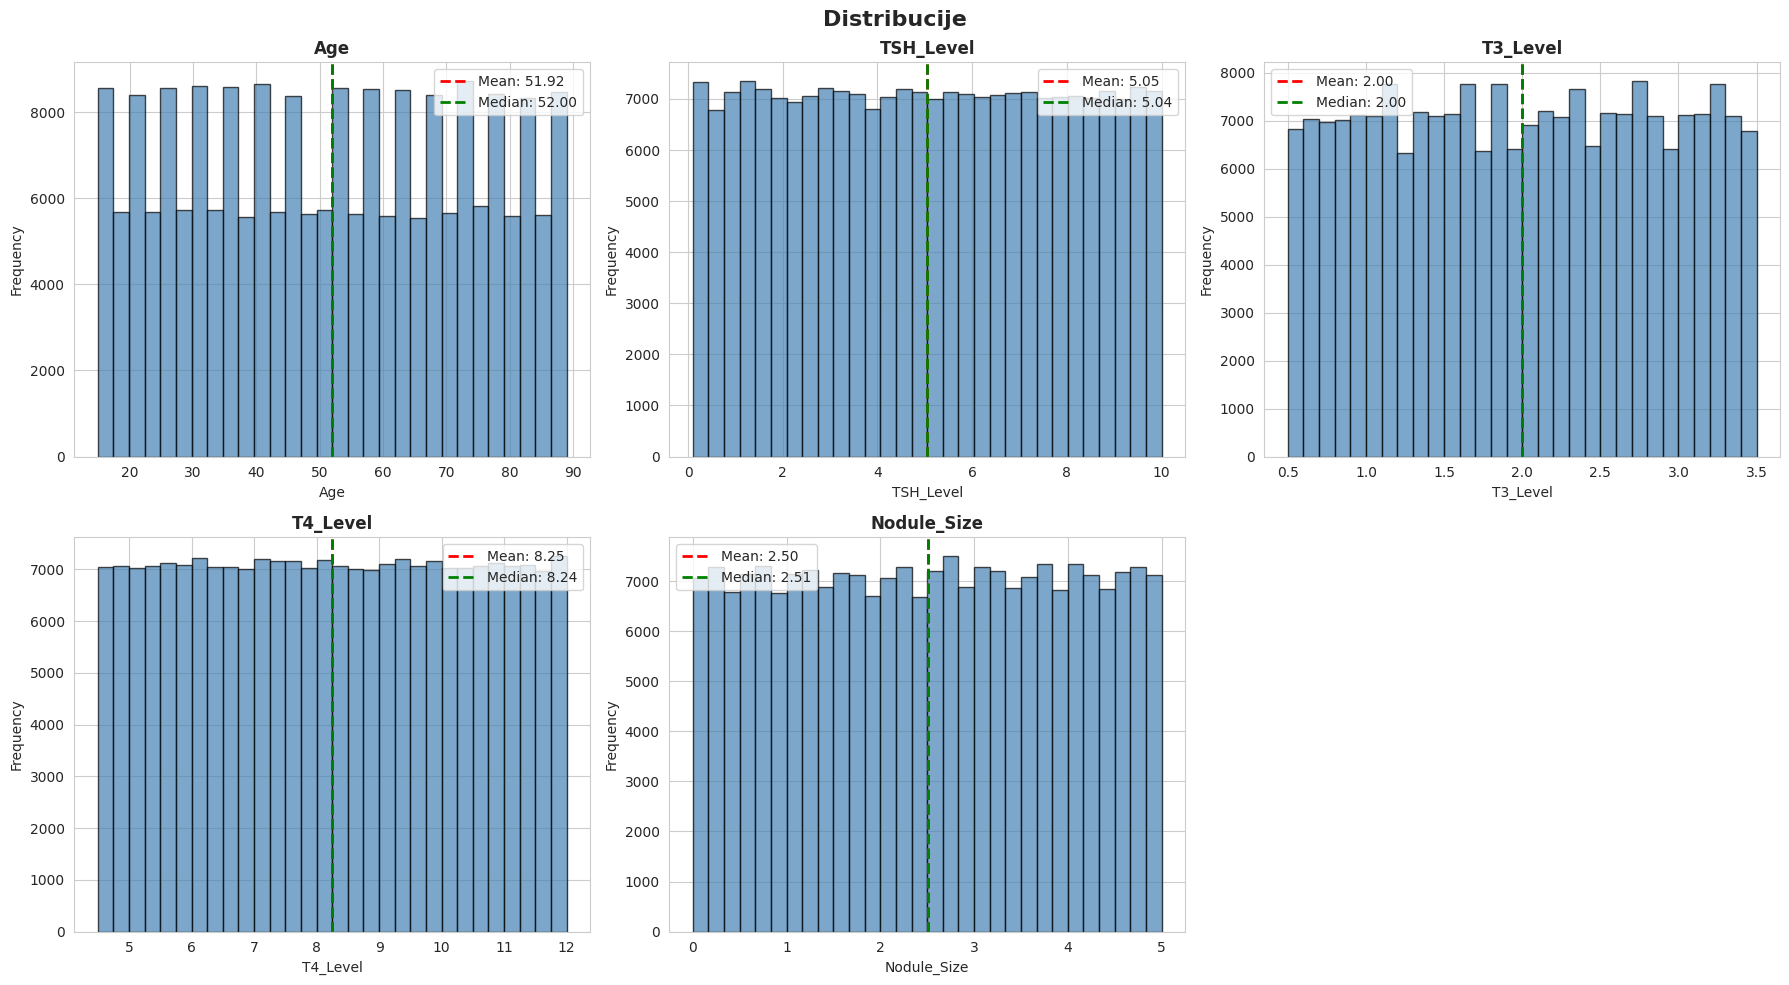

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Distribucije', fontsize=16, fontweight='bold')

for idx, col in enumerate(num_cols):
    row = idx // 3
    col_idx = idx % 3
    ax = axes[row, col_idx]
    
    df[col].hist(bins=30, ax=ax, color='steelblue', edgecolor='black', alpha=0.7)
    ax.axvline(df[col].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df[col].mean():.2f}')
    ax.axvline(df[col].median(), color='green', linestyle='--', linewidth=2, label=f'Median: {df[col].median():.2f}')
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
    ax.legend()

if len(num_cols) < 6:
    fig.delaxes(axes[1, 2])

plt.tight_layout()
plt.show()

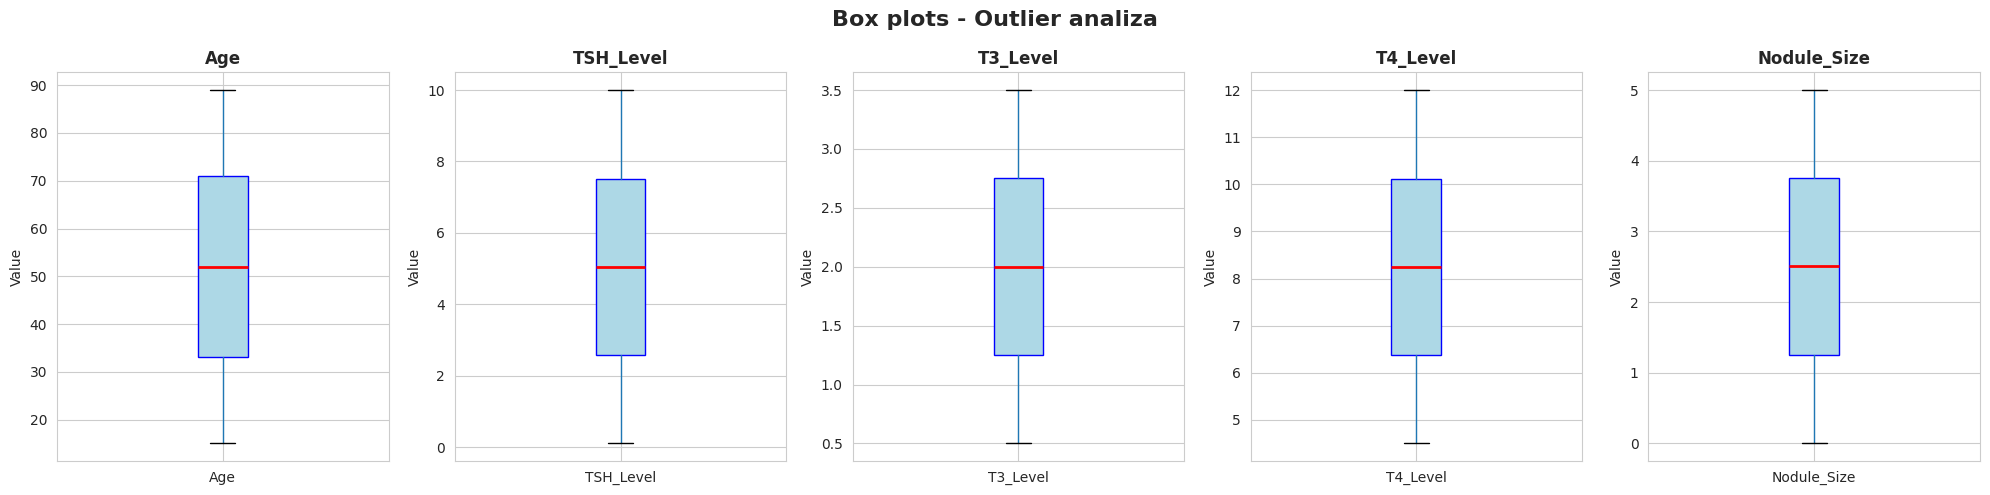

In [6]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(20, 5))
fig.suptitle('Box plots - Outlier analiza', fontsize=16, fontweight='bold')

for idx, col in enumerate(num_cols):
    ax = axes[idx]
    df.boxplot(column=col, ax=ax, patch_artist=True,
               boxprops=dict(facecolor='lightblue', color='blue'),
               medianprops=dict(color='red', linewidth=2))
    ax.set_title(col, fontweight='bold')
    ax.set_ylabel('Value')

plt.tight_layout()
plt.show()

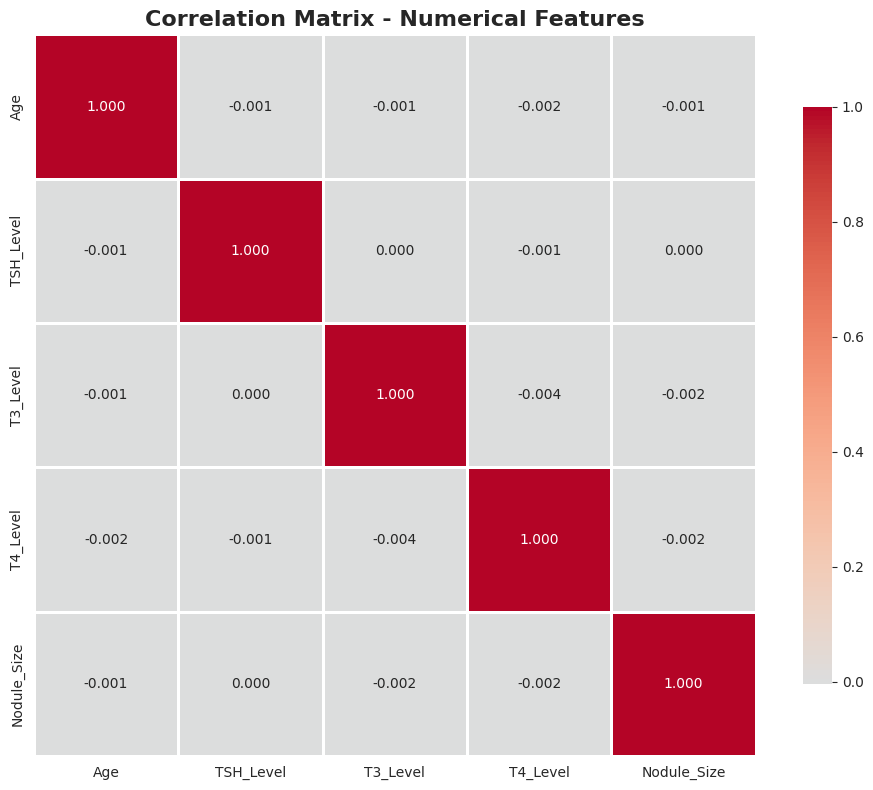


Korelaciona matrica:


,Age,TSH_Level,T3_Level,T4_Level,Nodule_Size
Age,1.000000,-0.000925,-0.001013,-0.002373,-0.001489
TSH_Level,-0.000925,1.000000,0.000335,-0.000795,0.000416
T3_Level,-0.001013,0.000335,1.000000,-0.004069,-0.001799
T4_Level,-0.002373,-0.000795,-0.004069,1.000000,-0.001860
Nodule_Size,-0.001489,0.000416,-0.001799,-0.001860,1.000000


In [7]:
corr = df[num_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm', center=0, 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix - Numerical Features', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nKorelaciona matrica:")
display(corr)

### Kategoricki atributi

In [8]:
display(df[cat_cols].describe())

,Gender,Country,Ethnicity,Family_History,Radiation_Exposure,Iodine_Deficiency,Smoking,Obesity,Diabetes,Thyroid_Cancer_Risk,Diagnosis
count,212691,212691,212691,212691,212691,212691,212691,212691,212691,212691,212691
unique,2,10,5,2,2,2,2,2,2,3,2
top,Female,India,Caucasian,No,No,No,No,No,No,Low,Benign
freq,127527,42496,63669,148866,180831,159673,170260,148805,170098,108388,163196


Interpretacija - Kategoričke varijable:
- **Gender**: Female 60%, Male 40%
- **Country**: 10 zemalja, balansirana distribucija (India 20%)
- **Binary features** (Family_History, Radiation, Smoking...): Većina **"No"** (70-85%)
- **Target (Diagnosis)**: Benign 76.7%, Malignant 23.3% → **class imbalance 3.3:1**

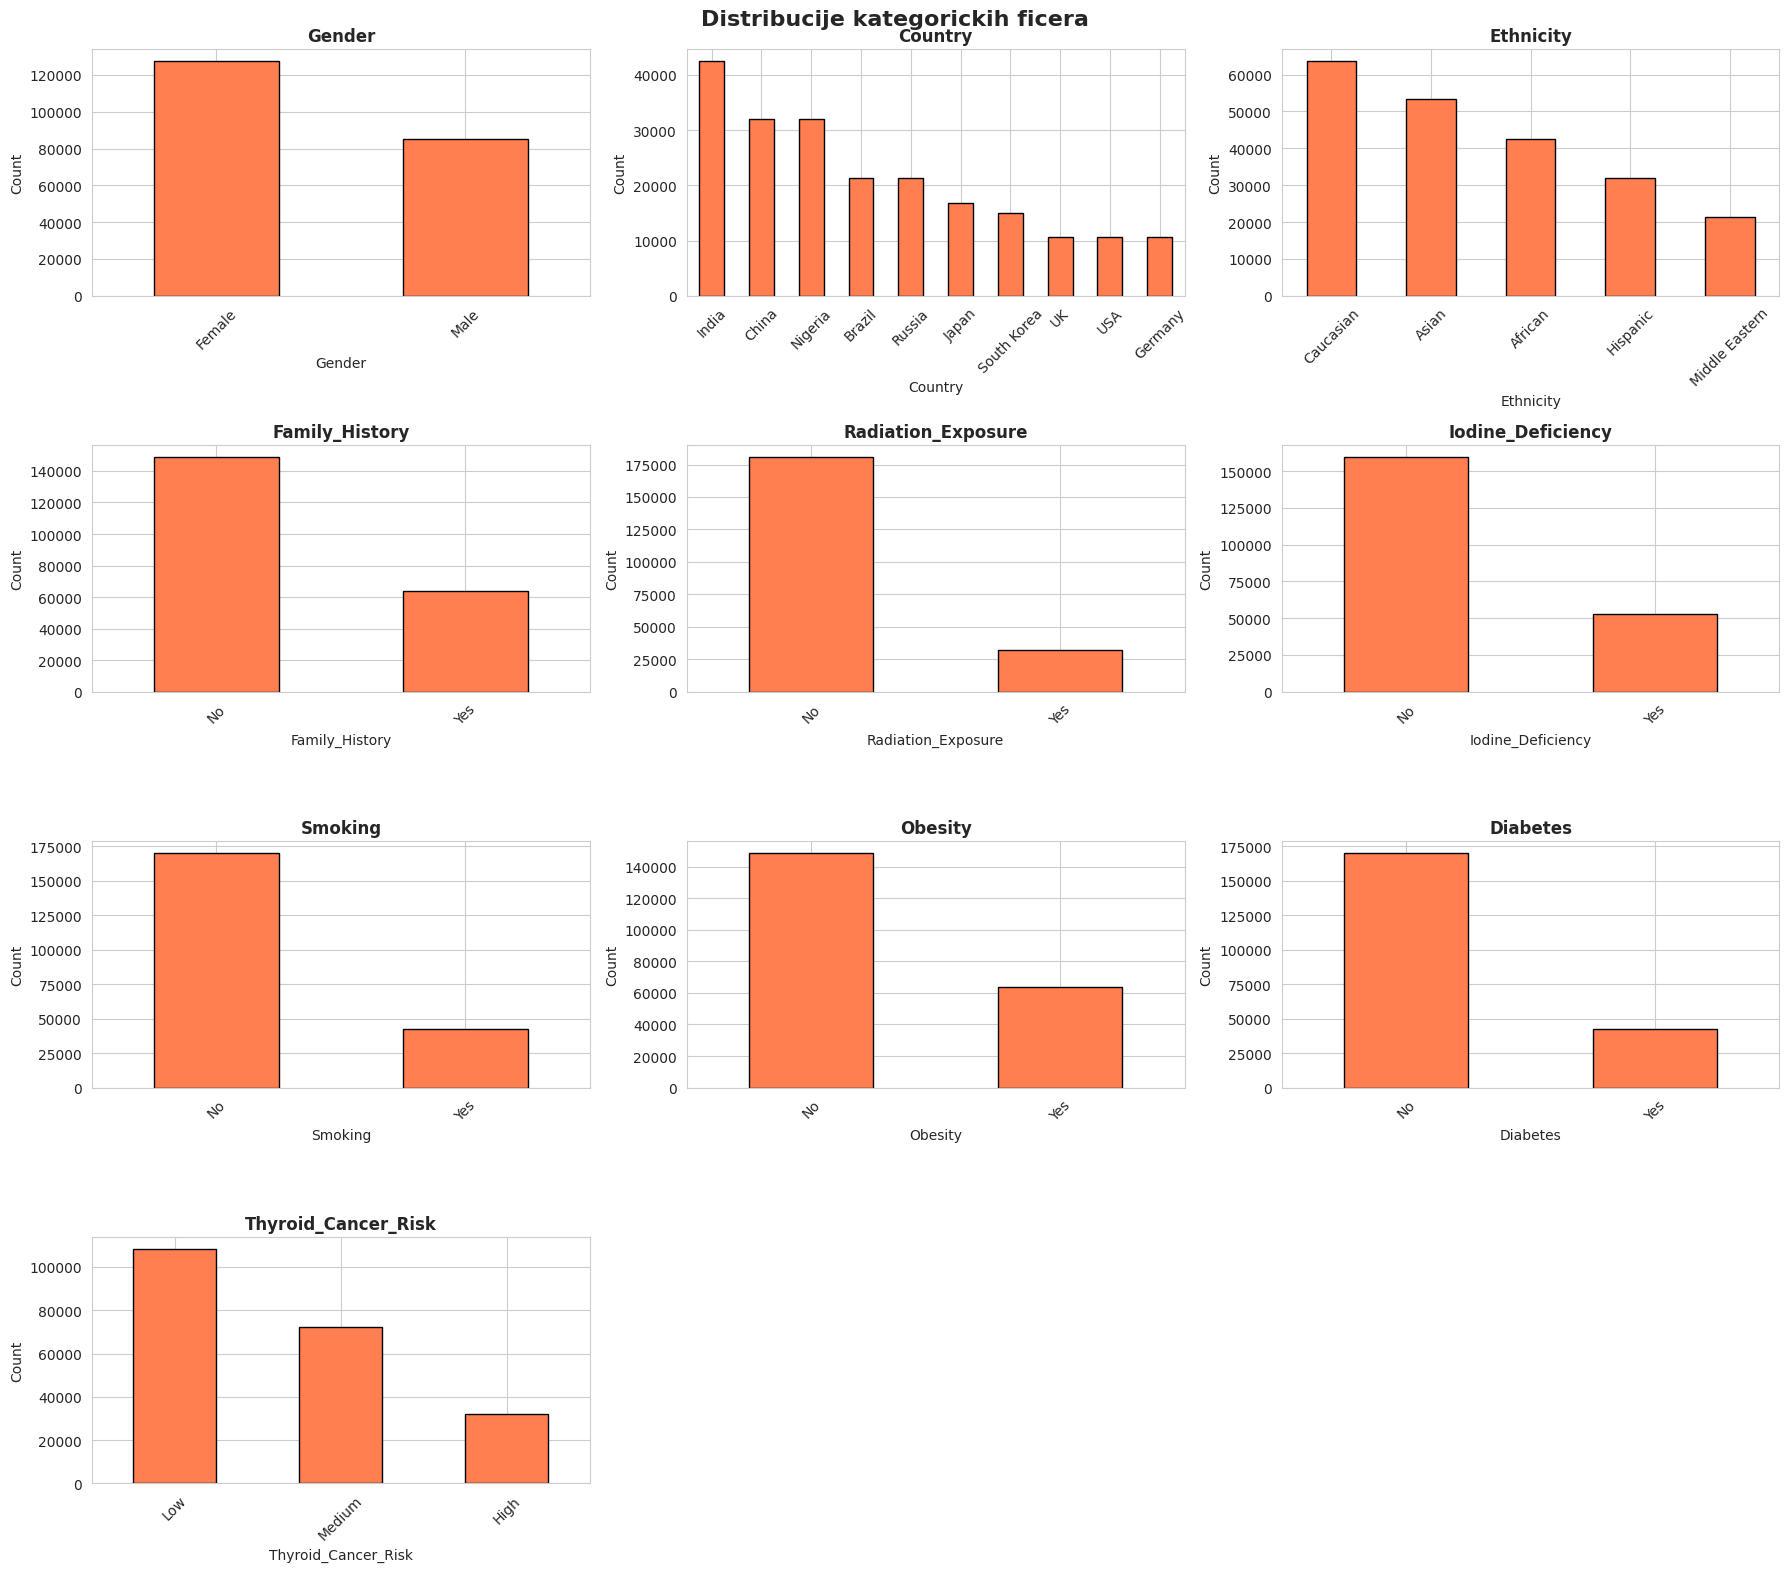

In [9]:
cat_features = [col for col in cat_cols if col != 'Diagnosis']

n_cols = 3
n_rows = int(np.ceil(len(cat_features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
fig.suptitle('Distribucije kategorickih ficera', fontsize=16, fontweight='bold')
axes = axes.ravel()

for idx, col in enumerate(cat_features):
    ax = axes[idx]
    vc = df[col].value_counts()
    vc.plot(kind='bar', ax=ax, color='coral', edgecolor='black')
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=45)

# Remove extra subplots
for idx in range(len(cat_features), len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()

### Ciljni atribut i analiza u odnosu na nezavisne atribute

,Count,Percentage
Diagnosis,,
Benign,163196,76.729152
Malignant,49495,23.270848



Class imbalance ratio: 3.30:1 (Benign:Malignant)


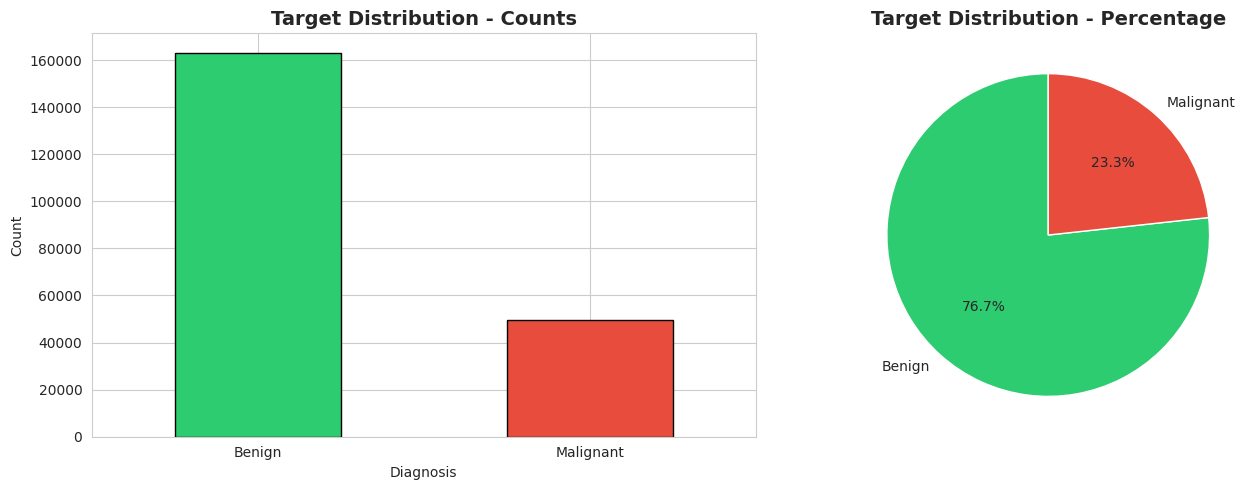

In [10]:
target_df = pd.DataFrame({
    'Count': df['Diagnosis'].value_counts(),
    'Percentage': df['Diagnosis'].value_counts(normalize=True) * 100
})
display(target_df)

ratio = target_df.loc['Benign', 'Count'] / target_df.loc['Malignant', 'Count']
print(f"\nClass imbalance ratio: {ratio:.2f}:1 (Benign:Malignant)")

# Vizuelizacija
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar plot
ax = axes[0]
target_df['Count'].plot(kind='bar', ax=ax, color=['#2ecc71', '#e74c3c'], edgecolor='black')
ax.set_title('Target Distribution - Counts', fontsize=14, fontweight='bold')
ax.set_xlabel('Diagnosis')
ax.set_ylabel('Count')
ax.tick_params(axis='x', rotation=0)

# Pie chart
ax = axes[1]
ax.pie(target_df['Count'], labels=target_df.index, autopct='%1.1f%%', 
       colors=['#2ecc71', '#e74c3c'], startangle=90)
ax.set_title('Target Distribution - Percentage', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

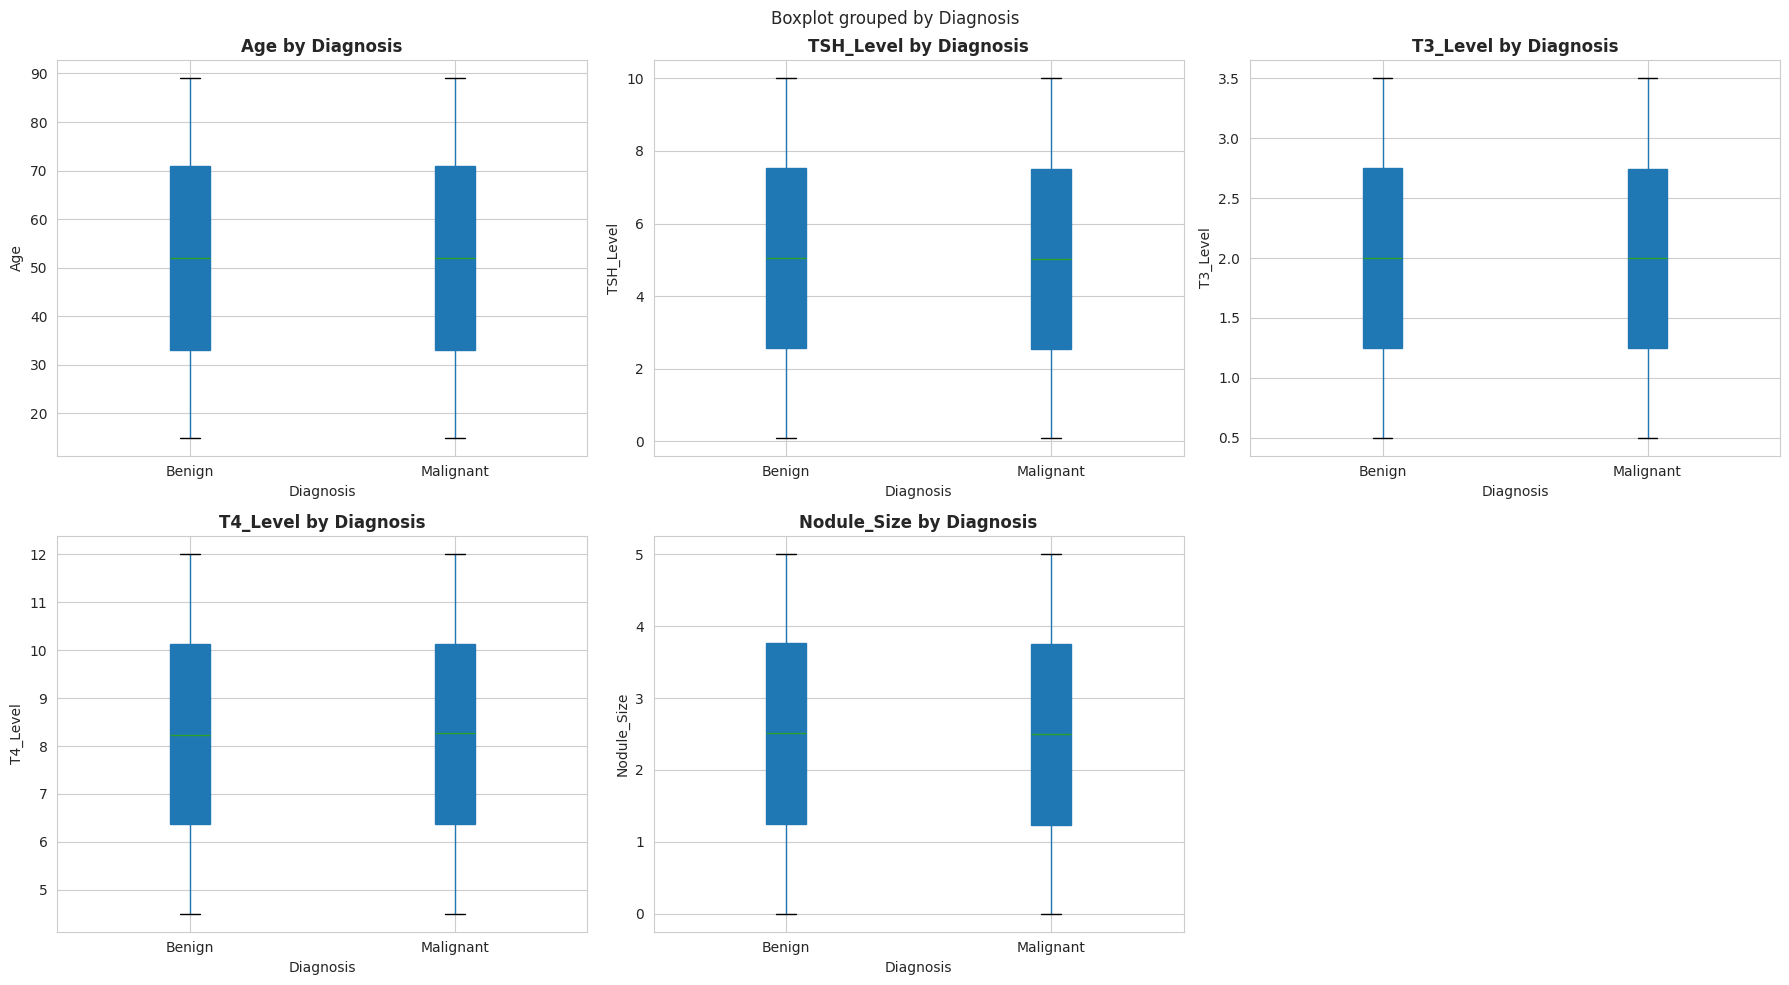

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Numerical by Diagnosis', fontsize=16, fontweight='bold')

for idx, col in enumerate(num_cols):
    row = idx // 3
    col_idx = idx % 3
    ax = axes[row, col_idx]
    
    df.boxplot(column=col, by='Diagnosis', ax=ax, patch_artist=True)
    ax.set_title(f'{col} by Diagnosis', fontweight='bold')
    ax.set_xlabel('Diagnosis')
    ax.set_ylabel(col)
    plt.sca(ax)
    plt.xticks(rotation=0)

# Remove extra subplot
if len(num_cols) < 6:
    fig.delaxes(axes[1, 2])

plt.tight_layout()
plt.show()

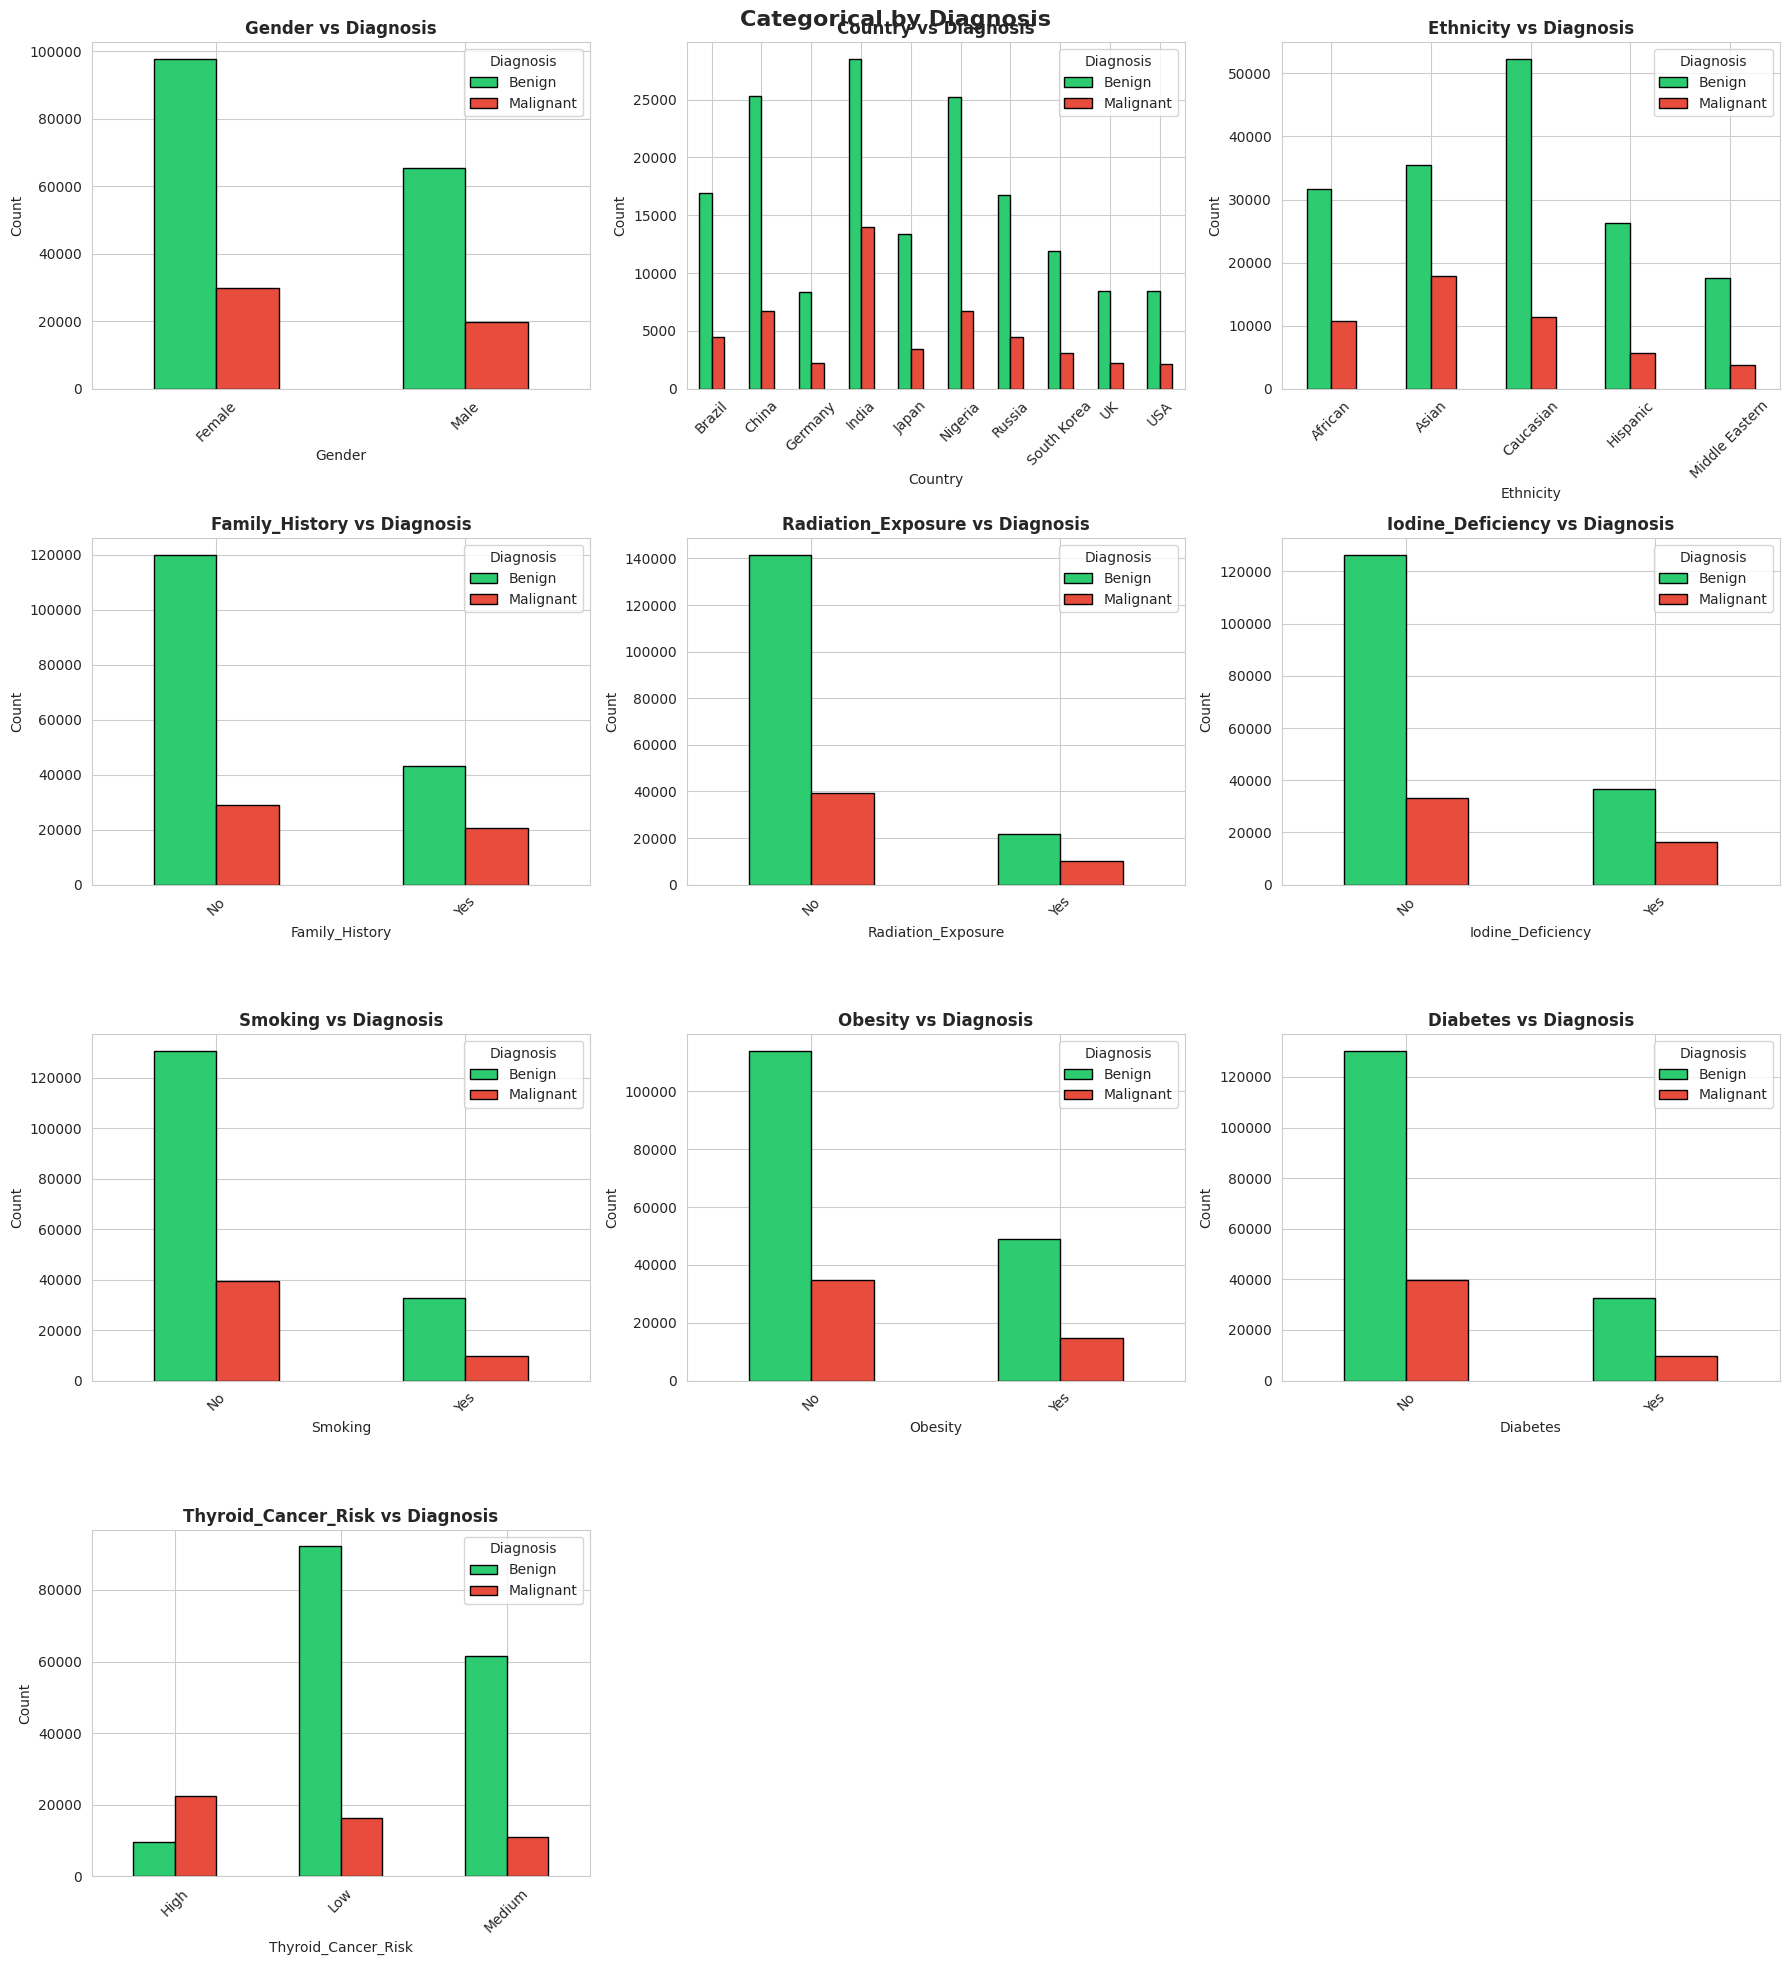

In [12]:
cat_features = [col for col in cat_cols if col not in ['Diagnosis']]

n_cols = 3
n_rows = int(np.ceil(len(cat_features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 5))
fig.suptitle('Categorical by Diagnosis', fontsize=16, fontweight='bold')
axes = axes.ravel()

for idx, col in enumerate(cat_features):
    ax = axes[idx]
    pd.crosstab(df[col], df['Diagnosis']).plot(kind='bar', ax=ax, 
                                                 color=['#2ecc71', '#e74c3c'],
                                                 edgecolor='black')
    ax.set_title(f'{col} vs Diagnosis', fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=45)
    ax.legend(title='Diagnosis', loc='upper right')

# Remove extra subplots
for idx in range(len(cat_features), len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()

### Automatsko generisanje EDA report-ova - YData Profiling

In [13]:
# https://docs.profiling.ydata.ai/latest/
# %pip install -U ydata-profiling
from ydata_profiling import ProfileReport

profile = ProfileReport(df, title="Thyroid Cancer - Pandas Profiling Report", explorative=True)
profile.to_file("thyroid_profiling_report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████████████████████████████████████████████████████| 16/16 [00:00<00:00, 54.87it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

### EDA - Zaključak
- **Dataset**: 212,691 obzervacija $\times$ 16 atributa (5 numerickih, 10 kategorickih, 1 ciljni). Nema nedostajucih vrednosti (dataset je prilicno "cist").
- **Numeričke varijable**: Uniformne distribucije (skewness $\sim$ 0), različite skale, nema multikolinearnosti.
- **Kategoričke varijable**: Mix binarnih i multi-class atributa. Većina binary atributa ima dominantnu "No" klasu (70-85%).
- **Target**: Class imbalance 3.3:1 (Benign 76.7%, Malignant 23.3%).
- **Za preprocessing**: Scaling, encoding, stratified split, class balancing.

## 3. Preprocesiranje (+ dodatna analiza/vizuelizacije)
Priprema podataka pred modeliranje:
- Enkodiranje kategorickih varijabli
- Scaling numerickih varijabli
- Kreiranje pipeline-a za reproducibilnost
- Korelaciona analiza nakon transformacije

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Podešavanja
pd.set_option('display.max_columns', None)

In [15]:
X = df.drop('Diagnosis', axis=1)
y = df['Diagnosis']

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"\nTarget distribution:")
display(y.value_counts())

X shape: (212691, 15)
y shape: (212691,)

Target distribution:


Diagnosis
Benign       163196
Malignant     49495
Name: count, dtype: int64

In [16]:
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

print(f"Numerical ({len(num_cols)}): {', '.join(num_cols)}")
print(f"Categorical ({len(cat_cols)}): {', '.join(cat_cols)}")

Numerical (5): Age, TSH_Level, T3_Level, T4_Level, Nodule_Size
Categorical (10): Gender, Country, Ethnicity, Family_History, Radiation_Exposure, Iodine_Deficiency, Smoking, Obesity, Diabetes, Thyroid_Cancer_Risk


### Enkodiranje kategorickih atributa

Za kategoricke atribute (svi su <b style="color: red">nominalni</b>) koristimo **OneHotEncoder** sa `drop='first'` da izbegnemo multikolinearnost ([dummy variable trap](https://www.statology.org/dummy-variable-trap/)).

In [17]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(drop='first', sparse_output=False)

X_cat_encoded = encoder.fit_transform(X[cat_cols])
encoded_feature_names = encoder.get_feature_names_out(cat_cols)

encoded_feature_names = [name.replace(' ', '_') for name in encoded_feature_names]
X_cat_df = pd.DataFrame(X_cat_encoded, columns=encoded_feature_names, index=X.index)

X_transformed = pd.concat([X[num_cols], X_cat_df], axis=1)

print(f"Originalni kategoricki atributi: {len(cat_cols)}")
print(f"Broj atributa nakon OneHot enkodiranja: {X_cat_encoded.shape[1]}")
print(f"\nUkupno atributa nakon enkodiranja: {X_transformed.shape[1]}")
print(f"\nNazivi kolona:")
print(", ".join(X_transformed.columns.tolist()), '\n')

display(X_transformed.head())

Originalni kategoricki atributi: 10
Broj atributa nakon OneHot enkodiranja: 22

Ukupno atributa nakon enkodiranja: 27

Nazivi kolona:
Age, TSH_Level, T3_Level, T4_Level, Nodule_Size, Gender_Male, Country_China, Country_Germany, Country_India, Country_Japan, Country_Nigeria, Country_Russia, Country_South_Korea, Country_UK, Country_USA, Ethnicity_Asian, Ethnicity_Caucasian, Ethnicity_Hispanic, Ethnicity_Middle_Eastern, Family_History_Yes, Radiation_Exposure_Yes, Iodine_Deficiency_Yes, Smoking_Yes, Obesity_Yes, Diabetes_Yes, Thyroid_Cancer_Risk_Low, Thyroid_Cancer_Risk_Medium 



,Age,TSH_Level,T3_Level,T4_Level,Nodule_Size,Gender_Male,Country_China,Country_Germany,Country_India,Country_Japan,Country_Nigeria,Country_Russia,Country_South_Korea,Country_UK,Country_USA,Ethnicity_Asian,Ethnicity_Caucasian,Ethnicity_Hispanic,Ethnicity_Middle_Eastern,Family_History_Yes,Radiation_Exposure_Yes,Iodine_Deficiency_Yes,Smoking_Yes,Obesity_Yes,Diabetes_Yes,Thyroid_Cancer_Risk_Low,Thyroid_Cancer_Risk_Medium
0,66,9.37,1.67,6.16,1.08,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,29,1.83,1.73,10.54,4.05,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,86,6.26,2.59,10.57,4.61,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,75,4.10,2.62,11.04,2.46,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,35,9.10,2.11,10.71,2.11,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


### Skaliranje numerickih atributa

Koristimo **StandardScaler** za normalizaciju numeričkih varijabli (mean=0, std=1).

In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_num_scaled = scaler.fit_transform(X_transformed[num_cols])
X_num_df = pd.DataFrame(X_num_scaled, columns=num_cols, index=X_transformed.index)

X_final = pd.concat([X_num_df, X_cat_df], axis=1)

print(f"Dimenzije nakon skaliranja: {X_final.shape}")
print(f"\nPrvih 5 redova:")
display(X_final.head())

print(f"\nProvera tacnosti skaliranja (mean = 0, std = 1):")
display(X_final[num_cols].describe())

Dimenzije nakon skaliranja: (212691, 27)

Prvih 5 redova:


,Age,TSH_Level,T3_Level,T4_Level,Nodule_Size,Gender_Male,Country_China,Country_Germany,Country_India,Country_Japan,Country_Nigeria,Country_Russia,Country_South_Korea,Country_UK,Country_USA,Ethnicity_Asian,Ethnicity_Caucasian,Ethnicity_Hispanic,Ethnicity_Middle_Eastern,Family_History_Yes,Radiation_Exposure_Yes,Iodine_Deficiency_Yes,Smoking_Yes,Obesity_Yes,Diabetes_Yes,Thyroid_Cancer_Risk_Low,Thyroid_Cancer_Risk_Medium
0,0.650934,1.512066,-0.382947,-0.963968,-0.985308,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-1.059435,-1.124060,-0.313683,1.059890,1.070585,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1.575458,0.424751,0.679107,1.073752,1.458229,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1.066970,-0.330426,0.713739,1.290924,-0.030045,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,-0.782077,1.417669,0.124991,1.138441,-0.272322,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0



Provera tacnosti skaliranja (mean = 0, std = 1):


,Age,TSH_Level,T3_Level,T4_Level,Nodule_Size
count,2.126910e+05,2.126910e+05,2.126910e+05,2.126910e+05,2.126910e+05
mean,2.244969e-17,-7.015528e-18,-1.808002e-16,1.330946e-16,7.349601e-18
std,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00
min,-1.706601e+00,-1.728901e+00,-1.733603e+00,-1.731001e+00,-1.732906e+00
25%,-8.745298e-01,-8.653424e-01,-8.677981e-01,-8.669339e-01,-8.676309e-01
50%,3.767582e-03,-1.783756e-03,-1.993240e-03,-2.866659e-03,4.566405e-03
75%,8.820650e-01,8.652711e-01,8.638116e-01,8.658213e-01,8.698415e-01
max,1.714136e+00,1.732326e+00,1.729617e+00,1.734509e+00,1.728194e+00


### Enkodiranje target-a

In [19]:
from sklearn.preprocessing import LabelEncoder

# Encode target: Benign=0, Malignant=1
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print(f"Original target:")
print(y.value_counts())
print(f"\nEncoded target:")
print(pd.Series(y_encoded).value_counts())
print(f"\nMapping: {dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))}")

Original target:
Diagnosis
Benign       163196
Malignant     49495
Name: count, dtype: int64

Encoded target:
0    163196
1     49495
Name: count, dtype: int64

Mapping: {'Benign': np.int64(0), 'Malignant': np.int64(1)}


### Ilustracije nakon transformacije (kratka analiza)

In [20]:
print("PRE TRANSFORMACIJE (Original)")
display(X.head())

print("POSLE TRANSFORMACIJE (Encoded + Scaled)")
display(X_final.head())

print(f"\nShape pre: {X.shape}")
print(f"Shape posle: {X_final.shape}")
print(f"Broj atributa se promenio sa {X.shape[1]} na {X_final.shape[1]}")

PRE TRANSFORMACIJE (Original)


,Age,Gender,Country,Ethnicity,Family_History,Radiation_Exposure,Iodine_Deficiency,Smoking,Obesity,Diabetes,TSH_Level,T3_Level,T4_Level,Nodule_Size,Thyroid_Cancer_Risk
0,66,Male,Russia,Caucasian,No,Yes,No,No,No,No,9.37,1.67,6.16,1.08,Low
1,29,Male,Germany,Hispanic,No,Yes,No,No,No,No,1.83,1.73,10.54,4.05,Low
2,86,Male,Nigeria,Caucasian,No,No,No,No,No,No,6.26,2.59,10.57,4.61,Low
3,75,Female,India,Asian,No,No,No,No,No,No,4.10,2.62,11.04,2.46,Medium
4,35,Female,Germany,African,Yes,Yes,No,No,No,No,9.10,2.11,10.71,2.11,High


POSLE TRANSFORMACIJE (Encoded + Scaled)


,Age,TSH_Level,T3_Level,T4_Level,Nodule_Size,Gender_Male,Country_China,Country_Germany,Country_India,Country_Japan,Country_Nigeria,Country_Russia,Country_South_Korea,Country_UK,Country_USA,Ethnicity_Asian,Ethnicity_Caucasian,Ethnicity_Hispanic,Ethnicity_Middle_Eastern,Family_History_Yes,Radiation_Exposure_Yes,Iodine_Deficiency_Yes,Smoking_Yes,Obesity_Yes,Diabetes_Yes,Thyroid_Cancer_Risk_Low,Thyroid_Cancer_Risk_Medium
0,0.650934,1.512066,-0.382947,-0.963968,-0.985308,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-1.059435,-1.124060,-0.313683,1.059890,1.070585,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1.575458,0.424751,0.679107,1.073752,1.458229,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1.066970,-0.330426,0.713739,1.290924,-0.030045,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,-0.782077,1.417669,0.124991,1.138441,-0.272322,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0



Shape pre: (212691, 15)
Shape posle: (212691, 27)
Broj atributa se promenio sa 15 na 27


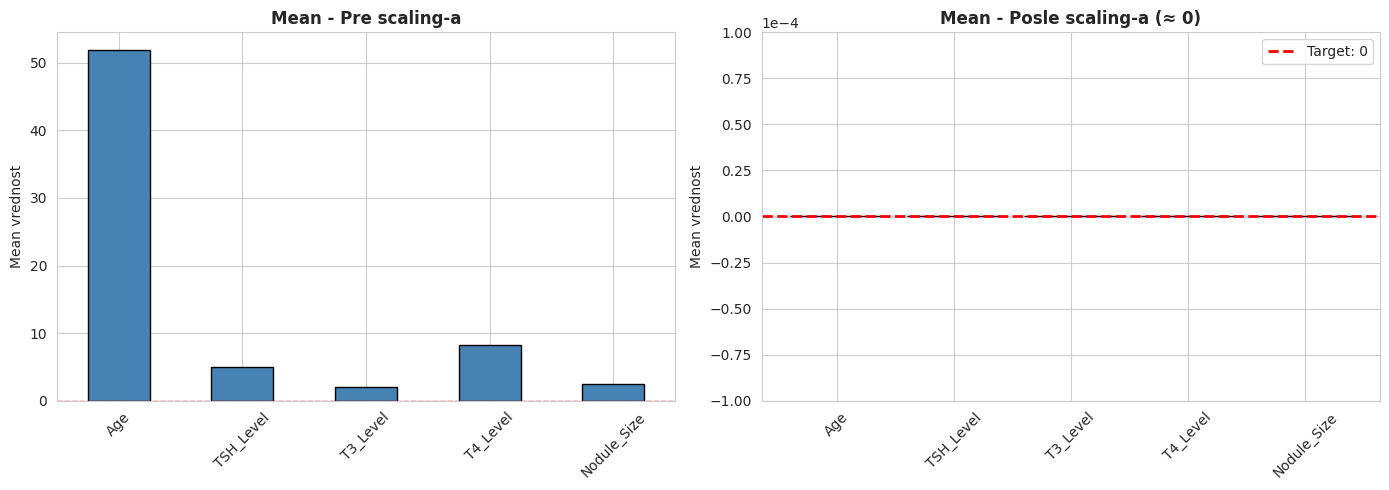

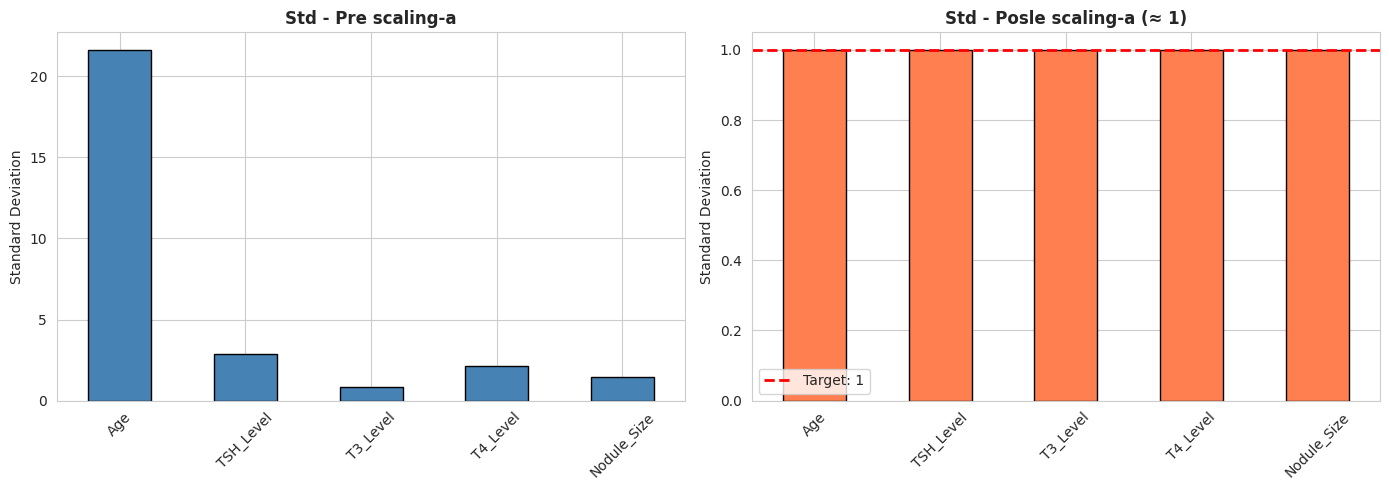

Scaling verifikacija:
Mean posle scaling-a: [ 2.24496908e-17 -7.01552837e-18 -1.80800188e-16  1.33094595e-16
  7.34960115e-18] (≈ 0)
Std posle scaling-a: [1.00000235 1.00000235 1.00000235 1.00000235 1.00000235] (≈ 1)


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pre scaling-a
ax = axes[0]
X[num_cols].mean().plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Mean - Pre scaling-a', fontweight='bold')
ax.set_ylabel('Mean vrednost')
ax.tick_params(axis='x', rotation=45)
ax.axhline(0, color='red', linestyle='--', linewidth=1)

# Posle scaling-a
ax = axes[1]
means_scaled = X_final[num_cols].mean()
ax.bar(range(len(num_cols)), means_scaled, color='coral', edgecolor='black')
ax.set_xticks(range(len(num_cols)))
ax.set_xticklabels(num_cols, rotation=45)
ax.set_title('Mean - Posle scaling-a (≈ 0)', fontweight='bold')
ax.set_ylabel('Mean vrednost')
ax.axhline(0, color='red', linestyle='--', linewidth=2, label='Target: 0')
ax.set_ylim(-0.0001, 0.0001)  # Zoom za prikaz blizu 0
ax.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
ax.legend()

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before
ax = axes[0]
X[num_cols].std().plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Std - Pre scaling-a', fontweight='bold')
ax.set_ylabel('Standard Deviation')
ax.tick_params(axis='x', rotation=45)

# After
ax = axes[1]
X_final[num_cols].std().plot(kind='bar', ax=ax, color='coral', edgecolor='black')
ax.set_title('Std - Posle scaling-a (≈ 1)', fontweight='bold')
ax.set_ylabel('Standard Deviation')
ax.tick_params(axis='x', rotation=45)
ax.axhline(1, color='red', linestyle='--', linewidth=2, label='Target: 1')
ax.legend()

plt.tight_layout()
plt.show()

print("Scaling verifikacija:")
print(f"Mean posle scaling-a: {X_final[num_cols].mean().values} (≈ 0)")
print(f"Std posle scaling-a: {X_final[num_cols].std().values} (≈ 1)")

Korelaciona matrica: (27, 27)


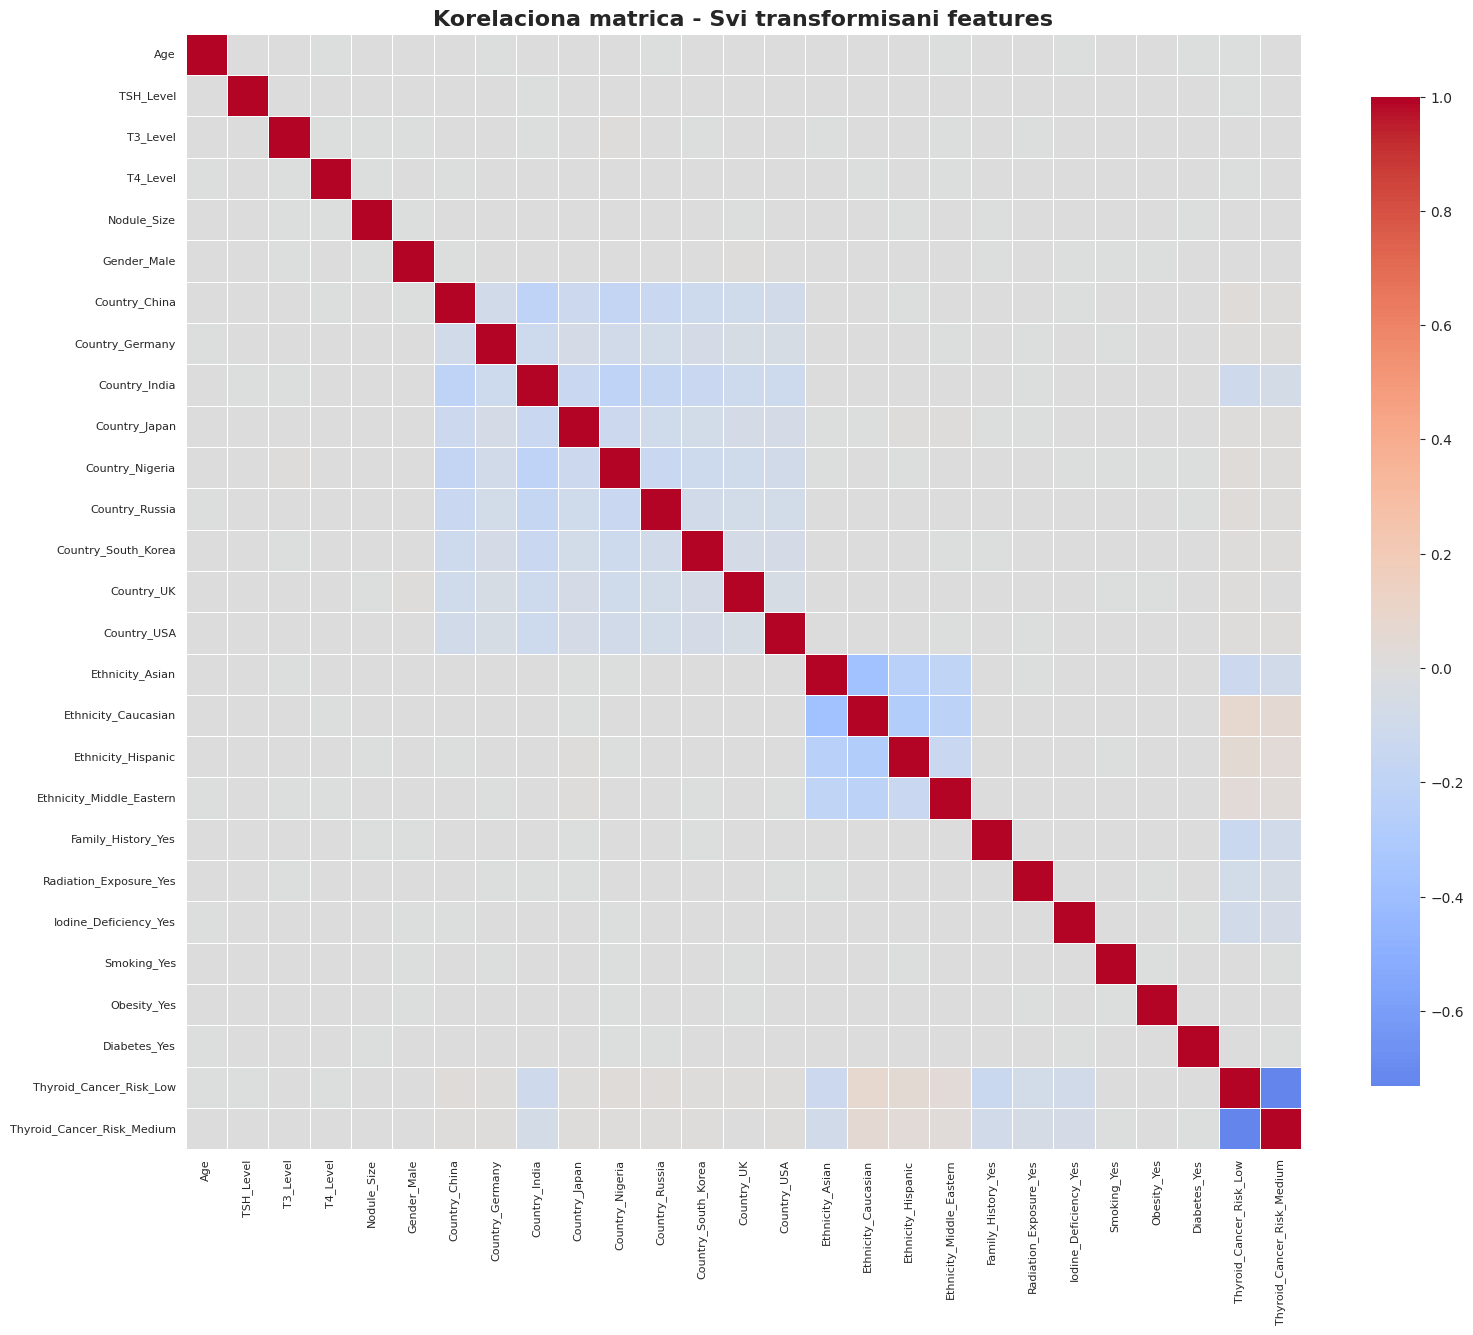

In [22]:
corr_matrix = X_final.corr()

print(f"Korelaciona matrica: {corr_matrix.shape}")

plt.figure(figsize=(16, 14))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, 
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            xticklabels=True, yticklabels=True)
plt.title('Korelaciona matrica - Svi transformisani features', fontsize=16, fontweight='bold')
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

Top 15 pozitivnih:


Family_History_Yes        0.140921
Ethnicity_Asian           0.139342
Country_India             0.113724
Iodine_Deficiency_Yes     0.099032
Radiation_Exposure_Yes    0.089043
T4_Level                  0.001216
Smoking_Yes               0.000862
Age                       0.000115
Obesity_Yes              -0.001233
Gender_Male              -0.001439
T3_Level                 -0.002388
Nodule_Size              -0.002658
TSH_Level                -0.002670
Diabetes_Yes             -0.003218
Country_Germany          -0.012280
Name: Diagnosis, dtype: float64


Top 15 negativnih:


TSH_Level                    -0.002670
Diabetes_Yes                 -0.003218
Country_Germany              -0.012280
Country_UK                   -0.012835
Country_Russia               -0.016643
Country_USA                  -0.017312
Country_South_Korea          -0.017380
Country_Japan                -0.018369
Country_Nigeria              -0.022294
Country_China                -0.023148
Ethnicity_Middle_Eastern     -0.042180
Ethnicity_Hispanic           -0.055092
Ethnicity_Caucasian          -0.083827
Thyroid_Cancer_Risk_Medium   -0.139178
Thyroid_Cancer_Risk_Low      -0.200045
Name: Diagnosis, dtype: float64

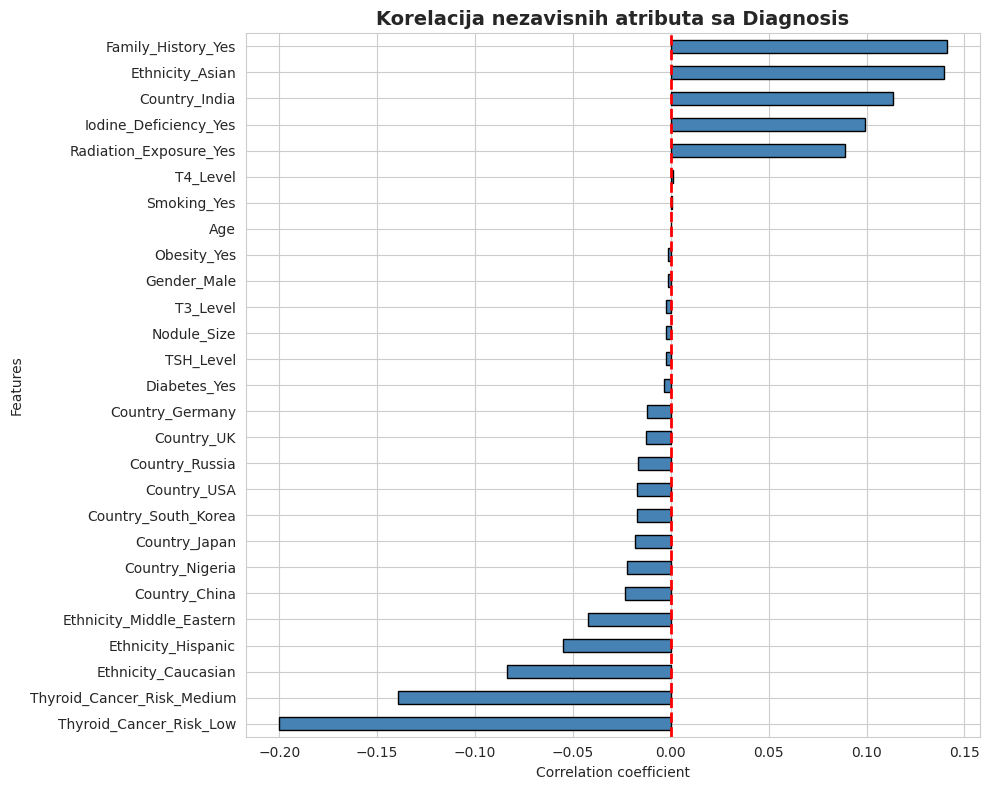

In [23]:
X_with_target = X_final.copy()
X_with_target['Diagnosis'] = y_encoded

target_corr = X_with_target.corr()['Diagnosis'].drop('Diagnosis').sort_values(ascending=False)

print("Top 15 pozitivnih:")
display(target_corr.head(15))

print("\nTop 15 negativnih:")
display(target_corr.tail(15))

fig, ax = plt.subplots(figsize=(10, 8))
target_corr.sort_values(ascending=True).plot(kind='barh', ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Korelacija nezavisnih atributa sa Diagnosis', fontsize=14, fontweight='bold')
ax.set_xlabel('Correlation coefficient')
ax.set_ylabel('Features')
ax.axvline(0, color='red', linestyle='--', linewidth=2)
plt.tight_layout()
plt.show()

### Kreiranje transformatora - reproducibilnost za downstream taskove

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(drop='first', sparse_output=False)

# ColumnTransformer - kombinuje transformacije
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)
    ])

# Test pipeline-a
X_pipeline = preprocessor.fit_transform(X)

print(f"Original X shape: {X.shape}")
print(f"Transformed X shape: {X_pipeline.shape}")
print(f"Broj atributa: {X.shape[1]} => {X_pipeline.shape[1]}")
print(f"Manual equal to Pipeline => {np.allclose(X_final.values, X_pipeline, rtol=1e-10)}")

Original X shape: (212691, 15)
Transformed X shape: (212691, 27)
Broj atributa: 15 => 27
Manual equal to Pipeline => True


In [25]:
display(preprocessor)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

### Preprocesiranje - zakljucak

Preprocessing zavrsen:
- Kategoricki atributi - `OneHotEncoder` (drop='first'): sa 9 na 20 atributa;
- Numericki atributi - `StandardScaler` (mean=0, std=1);
- Ukupno atributa nakon preprocesiranja: 15 => 25;
- Target => `LabelEncoder` (`Benign`=0, `Malignant`=1);
- Pipeline kreiran i verifikovano daje rezultate kao i manuelna predobrada;
- Korelacije nakon predobrade: Slabe (|r|<0.15), nema multikolinearnosti;

## 4. Evaluacija modela

Testiranje razlicitih klasifikacionih algoritama koristeći k-fold (stratified) cross-validation (k=10). Uporedjivanje sa baseline klasifikatorom (`DummyClassifier`) i izbor najboljih modela za dalje optimizovanje.

Cross-validation ce se raditi na 80% dataset-a, a 20% ce se ostaviti kao **hold-out** set, i koristice se na kraju, za dodatnu proveru kvaliteta modela.

(Kratka napomena: <em style="color: yellow;">SMOTE i druge tehnike resavanja nebalansiranosti ce se koristiti samo ako modeli koji podrzavaju "parameter to weight classes", tj. imaju `class_weights` argument, budu imali lose performanse, pa budemo primorani da koristimo druge modele</em>).

In [26]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.metrics import make_scorer, recall_score, precision_score, f1_score, roc_auc_score

import warnings
warnings.filterwarnings('ignore')
rand_state = 2026

### Hold-out set

In [27]:
from sklearn.model_selection import train_test_split

# Hold-out test set (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_final, 
    y_encoded, 
    test_size=0.2, 
    random_state=2026, 
    stratify=y_encoded
)

print(f"Total samples: {len(X_final)}")
print(f"Train set: {len(X_train)} samples ({len(X_train)/len(X_final)*100:.1f}%)")
print(f"Test set (hold-out): {len(X_test)} samples ({len(X_test)/len(X_final)*100:.1f}%)")

print(f"\nTarget distribution - Train:")
train_dist = pd.Series(y_train).value_counts(normalize=True) * 100
print(f"  Benign (0): {train_dist[0]:.2f}%")
print(f"  Malignant (1): {train_dist[1]:.2f}%")

print(f"\nTarget distribution - Test:")
test_dist = pd.Series(y_test).value_counts(normalize=True) * 100
print(f"  Benign (0): {test_dist[0]:.2f}%")
print(f"  Malignant (1): {test_dist[1]:.2f}%")

Total samples: 212691
Train set: 170152 samples (80.0%)
Test set (hold-out): 42539 samples (20.0%)

Target distribution - Train:
  Benign (0): 76.73%
  Malignant (1): 23.27%

Target distribution - Test:
  Benign (0): 76.73%
  Malignant (1): 23.27%


### Strategija cross-validation-a

In [28]:
# Stratified K-Fold Cross-Validation (k=5)
k = 5
cv_strategy = StratifiedKFold(n_splits=k, shuffle=True, random_state=rand_state)

print(f"Method: Stratified K-Fold")
print(f"Number folds: {k}")
print(f"Shuffle: True")
print(f"Random state: {rand_state}")
print(f"\nTotal samples: {len(X_train)}")
print(f"Samples per fold: ~{len(X_train)//k}")
print(f"Train samples per iter: ~{len(X_train)*(k-1)//k}")
print(f"Validation samples per iter: ~{len(X_train)//k}")

Method: Stratified K-Fold
Number folds: 5
Shuffle: True
Random state: 2026

Total samples: 170152
Samples per fold: ~34030
Train samples per iter: ~136121
Validation samples per iter: ~34030


### Metrike koriscene u evaluaciji

Primarne:
- Recall (Sensitivity): Kritično - minimizovati FN (`recall` jako bitan u medicini - lose je ako "promasimo" oboljenje - moze da dodje do terminalnog slucaja);
- Precision: Kontrolisanje FP;
- F1-Score: Balans između precision i recall (harmonijska sredina);
- ROC-AUC: Opsta metrika binarnih klasifikatora;

Sekundarne:
- Accuracy: Ukupna tacnost - nije previse reprezentativna zbog nebalansiranosti;

In [29]:
scoring = {
    'precision': make_scorer(precision_score, pos_label=1),
    'recall': make_scorer(recall_score, pos_label=1),
    'f1': make_scorer(f1_score, pos_label=1),
    'roc_auc': 'roc_auc',
    'accuracy': 'balanced_accuracy',
} # pos_label=1: Malignant klasa je pozitivna (vaznija za detekciju)

### Baseline model - `DummyClassifier`
- Svi modeli moraju biti bolji od ovoga - ako neki nije, nesto nije kako treba (ovo je sanity check);
- Vrsicemo cross-validation pomocu `stratified` modela, zato sto je relevantniji za konkretni problem (`most_frequent` strategija daje recall od 0, sto je vrlo lose za dati slucaj, iz prethodno pomenutih razloga);

In [30]:
from joblib import parallel_backend
import multiprocessing

number_cores = multiprocessing.cpu_count()
half_cores = number_cores // 2
cores_used = half_cores

results = {}
dummy_strategies = ['most_frequent', 'stratified']

for strategy in dummy_strategies:
    print(f"Strategy:  {strategy.upper().replace('_', ' ')}")

    dummy_clf = DummyClassifier(strategy=strategy, random_state=rand_state)

    with parallel_backend('threading', n_jobs=cores_used):
        cv_results = cross_validate(dummy_clf, X_train, y_train, 
                                    cv=cv_strategy, scoring=scoring, 
                                    return_train_score=False)

        results['baseline'] = {
            'accuracy': cv_results['test_accuracy'].mean(),
            'accuracy_std': cv_results['test_accuracy'].std(),
            'precision': cv_results['test_precision'].mean(),
            'precision_std': cv_results['test_precision'].std(),
            'recall': cv_results['test_recall'].mean(),
            'recall_std': cv_results['test_recall'].std(),
            'f1': cv_results['test_f1'].mean(),
            'f1_std': cv_results['test_f1'].std(),
            'roc_auc': cv_results['test_roc_auc'].mean(),
            'roc_auc_std': cv_results['test_roc_auc'].std()
        }
    
    print(f"Accuracy:  {results['baseline']['accuracy'].mean():.4f} +- {results['baseline']['accuracy_std'].std():.4f}")
    print(f"Precision: {results['baseline']['precision'].mean():.4f} +- {results['baseline']['precision_std'].std():.4f}")
    print(f"Recall:    {results['baseline']['recall'].mean():.4f} +- {results['baseline']['recall_std'].std():.4f}")
    print(f"F1-Score:  {results['baseline']['f1'].mean():.4f} +- {results['baseline']['f1_std'].std():.4f}")
    print(f"ROC-AUC:   {results['baseline']['roc_auc'].mean():.4f} +- {results['baseline']['roc_auc_std'].std():.4f}")
    print('\n')

dummy_clf = DummyClassifier(strategy='stratified', random_state=rand_state)
display(dummy_clf)

Strategy:  MOST FREQUENT
Accuracy:  0.5000 +- 0.0000
Precision: 0.0000 +- 0.0000
Recall:    0.0000 +- 0.0000
F1-Score:  0.0000 +- 0.0000
ROC-AUC:   0.5000 +- 0.0000


Strategy:  STRATIFIED
Accuracy:  0.5006 +- 0.0000
Precision: 0.2336 +- 0.0000
Recall:    0.2347 +- 0.0000
F1-Score:  0.2341 +- 0.0000
ROC-AUC:   0.5006 +- 0.0000




,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'stratified'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",2026
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None


### Testiranje raznih klasifikacionih modela

In [31]:
# Skup modela za testiranje
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', random_state=rand_state, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=rand_state),
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=rand_state),
    'XGBoost': XGBClassifier(scale_pos_weight=(y_train==0).sum()/(y_train==1).sum(), 
                             random_state=rand_state, eval_metric='logloss'),
    'LinearSVC': LinearSVC(class_weight='balanced', random_state=rand_state, max_iter=1000),
    'Naive Bayes': GaussianNB()
}
for model in models.values():
    display(model)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",2026
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",2026
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseud

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


- `KNeighborsClassifier` i `SVC` (SVM) nisu korisceni zbog velicine seta podataka.

In [32]:
for name, model in models.items():
    print(f"\n{name}...")
    
    with parallel_backend('threading', n_jobs=cores_used):
        cv_results = cross_validate(model, X_train, y_train, 
                                    cv=cv_strategy, scoring=scoring, 
                                    return_train_score=False)
        results[name] = {
            'accuracy': cv_results['test_accuracy'].mean(),
            'accuracy_std': cv_results['test_accuracy'].std(),
            'precision': cv_results['test_precision'].mean(),
            'precision_std': cv_results['test_precision'].std(),
            'recall': cv_results['test_recall'].mean(),
            'recall_std': cv_results['test_recall'].std(),
            'f1': cv_results['test_f1'].mean(),
            'f1_std': cv_results['test_f1'].std(),
            'roc_auc': cv_results['test_roc_auc'].mean(),
            'roc_auc_std': cv_results['test_roc_auc'].std()
        }
    
    print(f"  Accuracy:  {results[name]['accuracy']:.4f} +- {results[name]['accuracy_std']:.4f}")
    print(f"  Precision: {results[name]['precision']:.4f} +- {results[name]['precision_std']:.4f}")
    print(f"  Recall:    {results[name]['recall']:.4f} +- {results[name]['recall_std']:.4f}")
    print(f"  F1:        {results[name]['f1']:.4f} +- {results[name]['f1_std']:.4f}")

print("\nFinished.")


Logistic Regression...
  Accuracy:  0.6975 +- 0.0029
  Precision: 0.7016 +- 0.0068
  Recall:    0.4534 +- 0.0049
  F1:        0.5509 +- 0.0053

Decision Tree...
  Accuracy:  0.5980 +- 0.0017
  Precision: 0.3817 +- 0.0019
  Recall:    0.3855 +- 0.0041
  F1:        0.3836 +- 0.0029

Random Forest...
  Accuracy:  0.6889 +- 0.0022
  Precision: 0.7020 +- 0.0065
  Recall:    0.4337 +- 0.0035
  F1:        0.5362 +- 0.0042

XGBoost...
  Accuracy:  0.6909 +- 0.0031
  Precision: 0.6150 +- 0.0068
  Recall:    0.4713 +- 0.0051
  F1:        0.5336 +- 0.0054

LinearSVC...
  Accuracy:  0.6975 +- 0.0029
  Precision: 0.7016 +- 0.0068
  Recall:    0.4534 +- 0.0049
  F1:        0.5509 +- 0.0053

Naive Bayes...
  Accuracy:  0.6615 +- 0.0037
  Precision: 0.5242 +- 0.0066
  Recall:    0.4458 +- 0.0074
  F1:        0.4818 +- 0.0061

Finished.


In [33]:
results_df = pd.DataFrame(results).T
results_df = results_df.round(4)

display(results_df.sort_values(['f1', 'recall'], ascending=False)[['f1', 'recall', 'precision', 'accuracy', 'roc_auc']])

,f1,recall,precision,accuracy,roc_auc
Logistic Regression,0.5509,0.4534,0.7016,0.6975,0.6967
LinearSVC,0.5509,0.4534,0.7016,0.6975,0.6968
Random Forest,0.5362,0.4337,0.7020,0.6889,0.6972
XGBoost,0.5336,0.4713,0.6150,0.6909,0.6972
Naive Bayes,0.4818,0.4458,0.5242,0.6615,0.6862
Decision Tree,0.3836,0.3855,0.3817,0.5980,0.5980
baseline,0.2341,0.2347,0.2336,0.5006,0.5006


### Interpretacija rezultata i izbor modela za nastavak

Testirali smo 6 razlicitih klasifikatora koristeći stratified KFCV (k=5) na trening setu od 170k pacijenata (80% originalnog seta). Svi modeli prevazilaze baseline po bazicnim metrikama za klasifikatore (dummy classifier sa f1 i recall u okolini 0.23), sto potvrdjuje da nauceni sabloni postoje u podacima.

Rezultati pokazuju dve "grupe" klasifikatora. Logistic Regression i LinearSVC postigli su najveci recall, sto znaci da detektuju veci broj malignih slucajeva - kriticno za medicinski kontekst gde ne zelimo da propustimo stvarne slucajeve raka. S obzirom da daju gotovo identicne rezultate, uzecemo jedan od njih za nastavak. Tree-based modeli (Random Forest i XGBoost) pokazuju drugaciji malo slabije performanse, po pitanju svih metrika.

**Koje biramo za optimizaciju hiperparametara?**

1. `LogisticRegression` i `LinearSVC` - oba su vrlo efikasna (linearni su) i mogu da se "izbore" sa velikim skupom podataka (cak i ako koristimo brute force tune-ovanje hiperparametara);
2. `XGBoost` - malo slabije performanse od `RandomForest`-a, ali dosta brzi "ispod haube" (low hanging fruit za dodatno eksperimentisanje);

Dalje, optimizacijom hiperparametara ova tri modela, ocekujemo da nadjemo optimalnu konfiguraciju koja maksimizuje recall uz odrzavanje prihvatljivog precision-a (moze se reci da pokusavamo da "boost"-ujemo f1 score), sto je ultimativni cilj za detekciju karcinoma.

## 5. Selekcija modela - optimizacija hiperparametara

Optimizacija hiperparametara za top 3 modela koristeci GridSearchCV ili RandomizedSearchCV. Cilj - maksimizacija recall-a uz odrzavanje prihvatljivog precision-a (optimizacija F1-score-a).

In [34]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from scipy.stats import uniform, randint

import warnings
warnings.filterwarnings('ignore')

In [35]:
raise Exception("Stop here")

Exception: Stop here

### Optimizacija Logicstic Regression modela

In [40]:
# Parametri za tuning
param_grid_lr = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],  # Regularization strength
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga'],
    'max_iter': [50, 250, 1000]
}

# GridSearchCV
lr_model = LogisticRegression(class_weight='balanced', random_state=rand_state)

grid_search_lr = GridSearchCV(
    estimator=lr_model,
    param_grid=param_grid_lr,
    cv=cv_strategy,
    scoring=scoring,  # Optimizacija po F1 (balans recall/precision)
    refit='f1',
    verbose=1,
    return_train_score=False
)

with parallel_backend('threading', n_jobs=cores_used):
    grid_search_lr.fit(X_train, y_train)

print(f"\nBest parameters: {grid_search_lr.best_params_}")
print(f"Best F1-score: {grid_search_lr.best_score_:.4f}")

# Evaluacija najboljeg modela
best_lr = grid_search_lr.best_estimator_

Fitting 5 folds for each of 72 candidates, totalling 360 fits

Best parameters: {'C': 0.001, 'max_iter': 50, 'penalty': 'l1', 'solver': 'liblinear'}
Best F1-score: 0.5509


### XGBoost

In [ ]:
param_grid_xgb = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.3],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'min_child_weight': [1, 3, 5]
}

print(f"Total combinations: {3 * 3 * 3 * 3 * 3 * 3} = 729")

xgb_model = XGBClassifier(
    scale_pos_weight=(y_train==0).sum()/(y_train==1).sum(),
    random_state=rand_state,
    eval_metric='logloss',
    n_jobs=1,
    verbosity=1
)

random_search_xgb = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid_xgb,
    n_iter=50,
    cv=cv_strategy,
    scoring=scoring,
    n_jobs=cores_used,
    verbose=2,
    random_state=rand_state,
    return_train_score=False
)

with parallel_backend('threading', n_jobs=cores_used):
    random_search_xgb.fit(X_train, y_train)

print(f"\nBest parameters: {random_search_xgb.best_params_}")
print(f"Best F1-score: {random_search_xgb.best_score_:.4f}")

best_xgb = random_search_xgb.best_estimator_